## 1. Configuração e definição da função

In [ ]:
"""
Aproximacao de f(x) = 3 sen(2x) + 2 cos(5x) + 0.5 x^2 por uma MLP.
Dependencias: numpy, matplotlib, scikit-learn, torch
Execute: todas as células deste notebook, em ordem
"""
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

def f(x):
    return 3*np.sin(2*x) + 2*np.cos(5*x) + 0.5*x**2

## 2. Geração dos dados em [0, 10]

In [ ]:
# 1) Dados: 1.200 pontos em [0, 10]
x = np.linspace(0, 10, 1200, dtype=np.float32).reshape(-1, 1)
y = f(x).astype(np.float32)

## 3. Divisão treino/validação/teste e normalização sem vazamento

In [ ]:
# 2) Separacao: 70% treino, 15% validacao e 15% teste
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.30, random_state=SEED
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=SEED
)

# Escalonadores ajustados SOMENTE com os dados de treino
sx = StandardScaler().fit(x_train)
sy = StandardScaler().fit(y_train)

def tensor_escalonado(a, scaler):
    return torch.tensor(scaler.transform(a), dtype=torch.float32)

Xtr, Ytr = tensor_escalonado(x_train, sx), tensor_escalonado(y_train, sy)
Xva, Yva = tensor_escalonado(x_val, sx), tensor_escalonado(y_val, sy)
Xte = tensor_escalonado(x_test, sx)

## 4. Arquitetura MLP (1 → 64 → 64 → 1)

In [ ]:
# 3) MLP: 1 entrada -> 64 -> 64 -> 1 saida
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(1, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        return self.rede(x)

modelo = MLP()
otimizador = torch.optim.Adam(modelo.parameters(), lr=0.003, weight_decay=1e-6)
funcao_erro = nn.MSELoss()
lote = DataLoader(TensorDataset(Xtr, Ytr), batch_size=64, shuffle=True)

## 5. Treinamento, curvas de erro e parada antecipada

In [ ]:
# 4) Treinamento com validacao e parada antecipada
max_epocas, paciencia = 2500, 180
melhor_validacao = float("inf")
melhor_estado, melhor_epoca, espera = None, 0, 0
erros_treino, erros_validacao = [], []

for epoca in range(max_epocas):
    modelo.train()
    erros_lotes = []
    for xb, yb in lote:
        otimizador.zero_grad()
        perda = funcao_erro(modelo(xb), yb)
        perda.backward()
        otimizador.step()
        erros_lotes.append(perda.item())

    modelo.eval()
    with torch.no_grad():
        erro_val = funcao_erro(modelo(Xva), Yva).item()

    erros_treino.append(float(np.mean(erros_lotes)))
    erros_validacao.append(erro_val)

    if erro_val < melhor_validacao - 1e-7:
        melhor_validacao = erro_val
        melhor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        melhor_epoca = epoca + 1
        espera = 0
    else:
        espera += 1
    if espera >= paciencia:
        break

modelo.load_state_dict(melhor_estado)
modelo.eval()

def prever(a):
    with torch.no_grad():
        saida = modelo(tensor_escalonado(a, sx)).numpy()
    return sy.inverse_transform(saida)

## 6. Métricas finais no conjunto de teste

In [ ]:
# 5) Avaliacao final no conjunto de teste (nao usado para ajustar a rede)
y_pred = prever(x_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mse)

print(f"Epocas executadas: {len(erros_treino)}")
print(f"Melhor epoca (validacao): {melhor_epoca}")
print(f"MAE (teste):  {mae:.6f}")
print(f"MSE (teste):  {mse:.6f}")
print(f"RMSE (teste): {rmse:.6f}")

Epocas executadas: 1619
Melhor epoca (validacao): 1439
MAE (teste):  0.048513
MSE (teste):  0.003524
RMSE (teste): 0.059362


## 7. Gráficos: curva real, curva aproximada, erros e predições

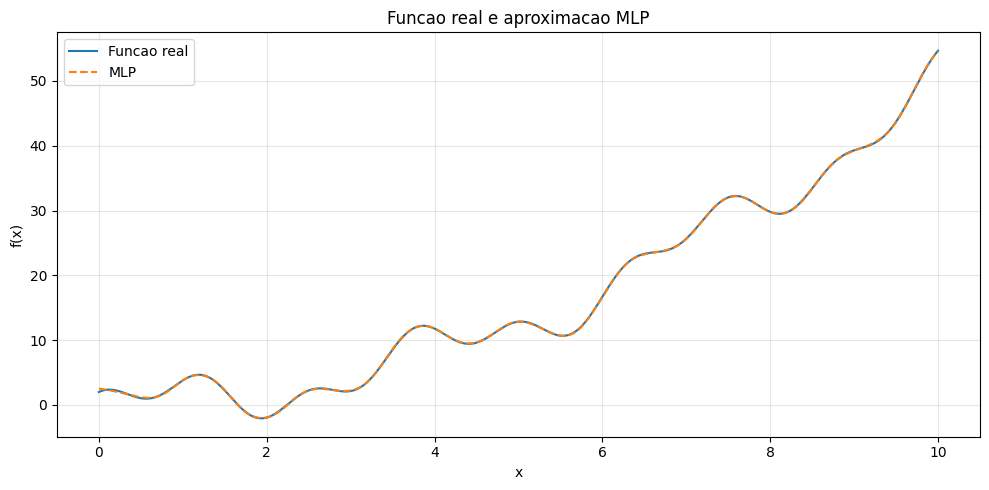

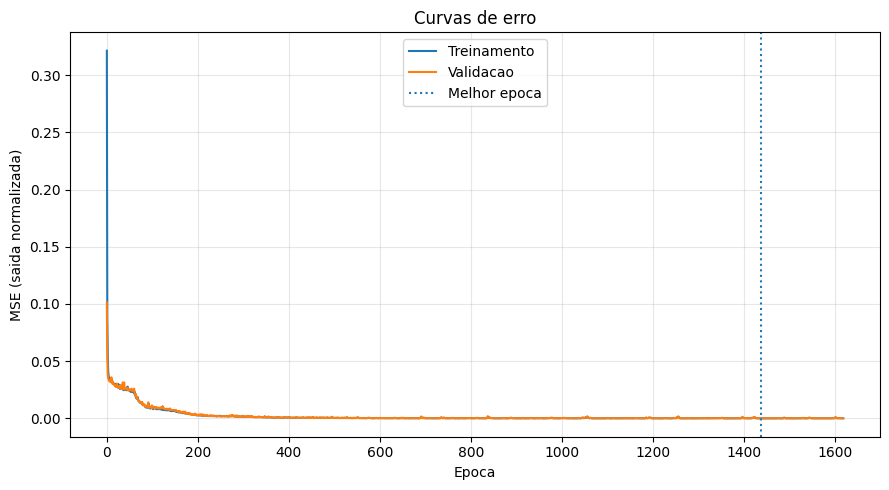

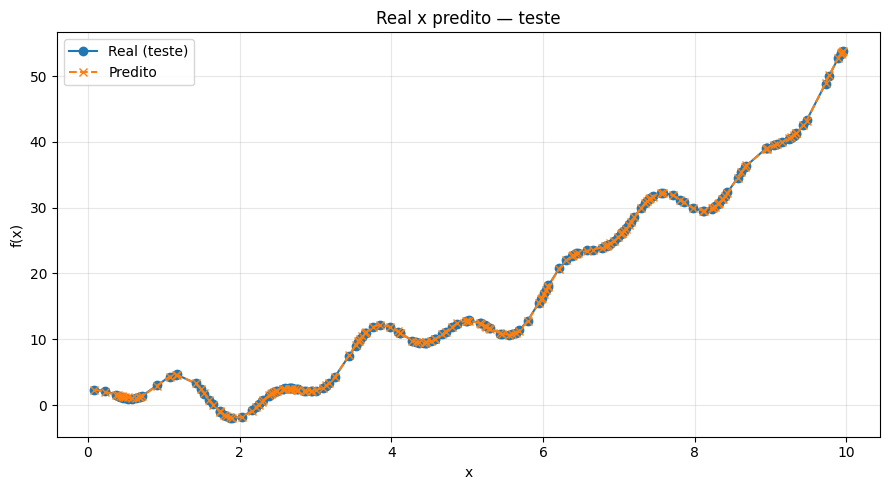

In [ ]:
# 6) Graficos
y_aprox = prever(x)
plt.figure(figsize=(10, 5))
plt.plot(x[:, 0], y[:, 0], label="Funcao real")
plt.plot(x[:, 0], y_aprox[:, 0], "--", label="MLP")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("Funcao real e aproximacao MLP")
plt.grid(True, alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig("aproximacao_mlp.png", dpi=180); plt.show()

plt.figure(figsize=(9, 5))
plt.plot(erros_treino, label="Treinamento")
plt.plot(erros_validacao, label="Validacao")
plt.axvline(melhor_epoca - 1, linestyle=":", label="Melhor epoca")
plt.xlabel("Epoca"); plt.ylabel("MSE (saida normalizada)")
plt.title("Curvas de erro")
plt.grid(True, alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig("curvas_erro_mlp.png", dpi=180); plt.show()

ordem = np.argsort(x_test[:, 0])
plt.figure(figsize=(9, 5))
plt.plot(x_test[ordem, 0], y_test[ordem, 0], "o-", label="Real (teste)")
plt.plot(x_test[ordem, 0], y_pred[ordem, 0], "x--", label="Predito")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("Real x predito — teste")
plt.grid(True, alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig("comparacao_teste_mlp.png", dpi=180); plt.show()

### Interpretação
O modelo realiza regressão; valores menores de MAE, MSE e RMSE indicam maior proximidade entre a curva real e a prevista. As curvas de treinamento e validação são apresentadas na escala **normalizada do alvo**, enquanto as métricas de teste são calculadas na escala real. A curva contínua em todo o intervalo é ilustrativa; o valor numérico das métricas usa somente o conjunto de teste.